**quantum_runs** - executed copy of `Shor.ipynb` (run `shor_sim_24q`).

Parameter overrides: `N_TO_FACTOR=221 BACKEND="cpu" LIVE_MEMORY_DISPLAY=False EXPORT_DIR="exports"`

# Shor's Algorithm - Integer Factorization
### Quantum order finding and factoring with NVIDIA CUDA-Q
*Notebook 3 of 8 - CUDA-Q Quantum Algorithm Benchmarking Suite*

This notebook factors a small composite integer with Shor's algorithm: quantum phase estimation finds the order of a modular multiplication, and classical number theory turns the order into factors. It explains and computes the qubit requirements, provides resource-estimation modes for larger integers, and benchmarks the simulation.

**How to use this notebook:** run all cells from top to bottom (*Kernel -> Restart & Run All*).
Change parameters **only in Section 3**; every later cell reads them from there. The default
configuration runs immediately on a laptop CPU and much faster on an NVIDIA GPU.

| Section | Content |
|---|---|
| 1 | Problem statement and mathematical explanation |
| 2 | Import libraries (with installation instructions) |
| 3 | Input parameters - **the only cell you need to edit** |
| 4 | Example inputs |
| 5 | Benchmark utilities and backend initialization |
| 6 | Expected output (computed *before* running the quantum circuit) |
| 7 | Quantum circuit generation and visualization |
| 8 | Execution with live memory monitoring |
| 9 | Results and visualization |
| 10 | Final benchmark report |

---
## Section 1 - Problem statement and mathematical explanation

### What problem does the algorithm solve?
**Integer factorization:** given a composite integer $N$, find non-trivial factors $p, q$ with $N = p\,q$.

### Why is this problem important?
The security of RSA public-key cryptography rests on factoring being hard. Shor's algorithm (1994) factors in
polynomial time on a fault-tolerant quantum computer, which is the main reason for today's migration to
post-quantum cryptography. It is also the textbook example of an exponential quantum speed-up.

### What is the classical approach?
Trial division costs $O(\sqrt N)$; the best known classical algorithm, the general number field sieve, runs in
sub-exponential time $\exp\!\big(O((\log N)^{1/3}(\log\log N)^{2/3})\big)$ - RSA-2048 is far out of reach.

### How does the quantum algorithm solve it?
**Reduction to order finding.** Pick $a$ with $1 < a < N$ and $\gcd(a, N) = 1$. The **order** $r$ is the smallest
positive integer with $a^r \equiv 1 \pmod N$. If $r$ is even and $a^{r/2} \not\equiv -1 \pmod N$, then

$$p = \gcd\!\left(a^{r/2} - 1,\; N\right),\qquad q = \gcd\!\left(a^{r/2} + 1,\; N\right)$$

are non-trivial factors. Finding $r$ is the hard part, and this is what the quantum computer does.

**Quantum phase estimation (QPE).** The unitary $U_a|y\rangle = |a\,y \bmod N\rangle$ (for $y < N$) permutes basis
states. Its eigenvalues are $e^{2\pi i\,s/r}$, $s = 0, \dots, r-1$, and the state $|1\rangle$ is an equal
superposition of the corresponding eigenvectors. The circuit uses two registers:

* **work register** - $n = \lceil \log_2 (N+1) \rceil$ qubits, initialised to $|1\rangle$;
* **counting register** - $t = 2n$ qubits in uniform superposition (enough precision that the continued-fraction
  step below recovers any $r \le N$, since $2^t \ge N^2$).

Counting qubit $j$ (weight $2^j$) controls $U_a^{2^j} = U_{a^{2^j} \bmod N}$, computed classically by repeated
squaring, so only $t$ controlled multiplications are needed. An **inverse QFT** on the counting register then
concentrates the probability at $y \approx 2^t\, s/r$.

**Classical post-processing.** Each measured $y$ gives a phase $y/2^t \approx s/r$; the **continued-fraction
expansion** (best rational approximation with denominator $\le N$) yields $r$ (or a divisor of it, so small
multiples are tested too). We check $a^r \equiv 1 \pmod N$ and compute the gcds above.

### Measurement
Only the counting register is measured. The outcomes cluster at the $r$ values $y \approx k\,2^t/r$; if $r$ divides
$2^t$ they are exact (e.g. $N = 15$, $a = 7$: $r = 4$, peaks at $y = 0, 64, 128, 192$ for $t = 8$).

### Qubit requirements
This notebook needs $t + n = 3n$ qubits ($N = 15$: $4 + 8 = 12$). The modular multiplications are implemented as exact
*permutation unitaries* (custom gates given to CUDA-Q as matrices). This is efficient for simulation and exact, but
it is **not** a gate-level fault-tolerant circuit: compiled circuits (e.g. Beauregard, $2n+3$ qubits) need many more gates.

### What is the expected solution?
For the default $N = 15$, $a = 7$: order $r = 4$, $7^2 = 49 \equiv 4$, so $\gcd(3, 15) = 3$ and $\gcd(5, 15) = 5$:
**$15 = 3 \times 5$**.

> **Important:** a classical simulator needs memory exponential in the number of qubits ($2^{3n}$ amplitudes here),
> so it can only "factor" tiny integers. The resource-estimation modes in Section 6 show what larger integers would
> need. Nothing in this notebook suggests that a simulator can factor large integers.

---
## Section 2 - Import libraries

All quantum code uses **NVIDIA CUDA-Q** (`cudaq`). The other libraries are standard scientific Python.

**Installation** (Linux x86_64/aarch64 with or without an NVIDIA GPU, or macOS on Apple silicon for CPU-only simulation):

```bash
python3 -m venv cudaq-env && source cudaq-env/bin/activate     # Python >= 3.11
pip install --upgrade pip
pip install cudaq numpy scipy matplotlib psutil nvidia-ml-py jupyter
```

* `pip install cudaq` detects your CUDA driver and installs the matching CUDA-Q build (CUDA 12.x or 13.x).
  A GPU is **not** required: CPU simulators are always available.
* `nvidia-ml-py` provides NVML bindings used for GPU memory monitoring (optional on CPU-only machines).
* Multi-GPU / multi-node runs additionally need MPI; see the README of this repository.

The next cell imports everything, prints the versions found and warns about incompatible versions.

In [1]:
# ---------------------------------------------------------------------------------
# Section 2 - Import libraries and check versions
# ---------------------------------------------------------------------------------
import os, sys, re, json, math, time, socket, platform      # standard library: files, timing, system info
import threading, subprocess, tempfile, datetime            # standard library: live memory monitor + report
import warnings                                             # used to hide two harmless CUDA-Q notices

# CUDA-Q 0.16 prints two informational warnings when imported: a "preview" notice for the
# bundled cudaq-logical package and a notice that sample/observe will change in a FUTURE
# release. Neither affects this notebook, so exactly these two messages are hidden.
warnings.filterwarnings("ignore", message=".*cudaq-logical is in preview.*")
warnings.filterwarnings("ignore", message=".*algorithmic primitives will change.*")

_missing = []                                               # collect missing packages for one clear message
try:
    import numpy as np                                      # arrays, linear algebra, random numbers
except ImportError:
    _missing.append("numpy")
try:
    import matplotlib                                       # plotting library
    import matplotlib.pyplot as plt                         # pyplot interface for figures
except ImportError:
    _missing.append("matplotlib")
try:
    import scipy                                            # scientific computing (optimizers, linear algebra)
    from fractions import Fraction                    # continued fractions (exact rational arithmetic)
except ImportError:
    _missing.append("scipy")
try:
    import psutil                                           # host RAM monitoring
except ImportError:
    _missing.append("psutil")
try:
    import cudaq                                            # NVIDIA CUDA-Q: kernels, simulators, QPU targets
except ImportError:
    _missing.append("cudaq")
if _missing:
    raise ImportError(f"Missing packages: {_missing}. Install them with:\n"
                      f"    pip install {' '.join(_missing)} nvidia-ml-py\n"
                      "CUDA-Q needs Linux (x86_64/aarch64) or macOS on Apple silicon (CPU only); see README.md.")

try:
    import pynvml                                           # NVIDIA Management Library bindings (GPU memory)
    HAVE_NVML = True
except ImportError:                                         # optional: only needed for GPU monitoring
    pynvml, HAVE_NVML = None, False

try:                                                        # live display inside Jupyter
    from IPython import get_ipython
    from IPython.display import display, Pretty
    _IN_JUPYTER = get_ipython() is not None and "IPKernelApp" in get_ipython().config
except Exception:                                           # running as a plain Python script
    display, Pretty, _IN_JUPYTER = None, None, False

# ---- Version report and compatibility check ----------------------------------------
_match = re.search(r"(\d+)\.(\d+)\.(\d+)", cudaq.__version__)
CUDAQ_VERSION = ".".join(_match.groups()) if _match else cudaq.__version__
_cudaq_tuple = tuple(int(x) for x in _match.groups()) if _match else (0, 0, 0)
print(f"Python      : {platform.python_version()} ({platform.system()} {platform.machine()})")
print(f"CUDA-Q      : {CUDAQ_VERSION}")
print(f"NumPy       : {np.__version__}")
print(f"SciPy       : {scipy.__version__}")
print(f"Matplotlib  : {matplotlib.__version__}")
print(f"psutil      : {psutil.__version__}")
print(f"nvidia-ml-py: {'installed' if HAVE_NVML else 'NOT installed (GPU memory monitoring disabled: pip install nvidia-ml-py)'}")
print(f"GPUs visible to CUDA-Q: {cudaq.num_available_gpus()}")
if sys.version_info < (3, 11):
    print("WARNING: CUDA-Q 0.16 wheels require Python >= 3.11.")
if _cudaq_tuple < (0, 12, 0):
    print("WARNING: this notebook was written and tested with CUDA-Q 0.16.0; versions older than 0.12 "
          "use a different operator API and are not supported. Upgrade with: pip install -U cudaq")
elif _cudaq_tuple != (0, 16, 0):
    print("Note: tested with CUDA-Q 0.16.0. Other versions should work; if an API error appears, "
          "compare with the README's 'Known limitations'.")

# ---------------------------------------------------------------------------------
# Plot style used by every figure: colour-blind-safe palette, hairline grid, one y-axis per chart
# ---------------------------------------------------------------------------------
# Categorical colours in a FIXED order (validated for colour-vision deficiency).
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, AQUA = SERIES_COLORS[0], SERIES_COLORS[1], SERIES_COLORS[2]
INK, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"   # text colours
GRID_COLOR, AXIS_COLOR, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"  # chart chrome
GOOD, CRITICAL = "#0ca30c", "#d03b3b"                                # reserved status colours
SEQUENTIAL_BLUE = matplotlib.colors.LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])          # magnitude
DIVERGING_BLUE_RED = matplotlib.colors.LinearSegmentedColormap.from_list(
    "div_blue_red", ["#184f95", "#6da7ec", "#f0efec", "#ec8a89", "#a32b2b"])      # signed values


def apply_plot_style():
    """Consistent, quiet chart style for every figure in this notebook."""
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "axes.edgecolor": AXIS_COLOR, "axes.labelcolor": INK_SECONDARY, "axes.titlecolor": INK,
        "text.color": INK, "xtick.color": AXIS_COLOR, "ytick.color": AXIS_COLOR,
        "xtick.labelcolor": INK_SECONDARY, "ytick.labelcolor": INK_SECONDARY,
        "axes.grid": True, "grid.color": GRID_COLOR, "grid.linewidth": 0.8, "grid.linestyle": "-",
        "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
        "axes.prop_cycle": matplotlib.cycler(color=SERIES_COLORS),
        "lines.linewidth": 2.0, "lines.solid_capstyle": "round", "lines.markersize": 6,
        "legend.frameon": False, "font.size": 10, "axes.titlesize": 11, "figure.dpi": 100,
    })


apply_plot_style()

Python      : 3.13.18 (Linux x86_64)
CUDA-Q      : 0.16.0
NumPy       : 2.5.4
SciPy       : 1.18.1
Matplotlib  : 3.11.2
psutil      : 7.2.2
nvidia-ml-py: NOT installed (GPU memory monitoring disabled: pip install nvidia-ml-py)
GPUs visible to CUDA-Q: 0


---
## Section 3 - Input parameters

This is the **only cell you need to edit**. Every later cell reads these variables.

In [2]:
# =====================================================================================
# Section 3 - INPUT PARAMETERS  (edit only this cell, then re-run the notebook)
# =====================================================================================

# ---- Problem definition -----------------------------------------------------------------
N_TO_FACTOR = 221                 # odd composite integer, not a prime power. Qubits needed = 3 x bits(N):
                                 # 15 -> 12 qubits, 21 -> 15, 33/35 -> 18, 55/57 -> 18, 91 -> 21, 143 -> 24
BASE_A = 7                       # 1 < a < N with gcd(a, N) = 1; None = random (Shor's original recipe, seeded)
NUM_COUNTING_QUBITS = None       # None = 2n (precision needed for continued fractions); or an integer
MAX_ATTEMPTS = 5                 # retries with a new random a if an attempt fails (odd order, trivial factor)
MAX_SIMULATION_QUBITS = 26       # never simulate circuits wider than this (estimation-only above)

# ---- Resource-estimation modes (no simulation needed) ---------------------------------------
ESTIMATE_BITS = [4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048, 4096]   # integer sizes (bits) to tabulate
QUBIT_BUDGET = 100               # reverse mode: largest integer that fits into this many (logical) qubits
MEMORY_BUDGET_GB = 80.0          # reverse mode: largest integer THIS notebook could simulate with this memory

# ---- Backend and simulation method ---------------------------------------------------
BACKEND = "cpu"                 # "auto" | "cpu" | "gpu" | "multi-gpu" | "hardware"
SIMULATION_METHOD = "statevector"   # this notebook supports: "statevector" | "density_matrix"
GPU_PRECISION = "fp64"            # "fp64" (16 B/amplitude) | "fp32" (8 B/amplitude, half the memory)
HARDWARE_PROVIDER = "quantinuum"  # only for BACKEND="hardware": "quantinuum", "ionq", "oqc", "anyon", "infleqtion", ...
HARDWARE_EMULATE = True           # True: local emulation (no account, no cost); False: real QPU (credentials needed)
HARDWARE_MACHINE = None           # provider device name, e.g. "H2-1E"; None = provider default

# ---- Shots and reproducibility --------------------------------------------------------
SHOTS = 1000                       # measurement repetitions; statistical error ~ 1/sqrt(SHOTS)
SEED = 42                         # fixes NumPy and CUDA-Q random numbers -> reproducible results

# ---- Memory monitoring ----------------------------------------------------------------
LIVE_MEMORY_DISPLAY = False        # live RAM / GPU memory line while the execution cell runs
MEMORY_SAMPLE_INTERVAL_S = 0.25   # sampling period in seconds (smaller = finer timeline)
MEMORY_SAFETY_FRACTION = 0.8      # refuse runs whose state needs more than 80% of free memory

# ---- Circuit drawing, export and report ---------------------------------------------------
DRAW_QUBITS = 10                  # qubits shown in the circuit drawing (maximum 10)
EXPORT_CIRCUIT = True             # save drawing + full circuit to EXPORT_DIR
EXPORT_FORMATS = ["txt", "png", "qir"]   # "txt", "png" (drawing), "qir", "qasm" (full circuit)
EXPORT_DIR = "exports"     # output folder (created automatically)
SAVE_REPORT = True                # save the final benchmark report (JSON) and figure (PNG)

#### What every parameter means and what happens when you change it

| Parameter | Meaning | Effect of changing it |
|---|---|---|
| `N_TO_FACTOR` | The integer $N$ to factor. | Qubits grow as $3\lceil\log_2(N+1)\rceil$, simulation memory as $16 \cdot 2^{3n}$ bytes: $N=15$: 12 qubits (65 KB), $N=143$: 24 qubits (268 MB), $N=1023$: 30 qubits (17 GB). Even numbers, primes and prime powers are detected and handled classically. |
| `BASE_A` | The base $a$ of the modular exponentiation. | Different $a$ have different orders $r$ (different peak patterns). Some $a$ fail (odd $r$ or $a^{r/2} \equiv -1$); then a new random $a$ is tried. If $\gcd(a,N) > 1$ the notebook switches to a random valid $a$. |
| `NUM_COUNTING_QUBITS` | Precision $t$ of the phase estimate. | Fewer than $2n$ qubits can make the continued-fraction step fail; more qubits sharpen the peaks but cost memory. |
| `MAX_ATTEMPTS` | Number of $a$ values tried. | Each attempt is one quantum run; the success probability per attempt is at least ~1/2 for most $N$. |
| `MAX_SIMULATION_QUBITS` | Safety limit for simulation. | Above it the notebook only shows resource estimates. |
| `ESTIMATE_BITS` | Integer sizes for the resource table. | Display only (no simulation). |
| `QUBIT_BUDGET` / `MEMORY_BUDGET_GB` | Inputs of the reverse estimation mode. | Shows the largest integer representable with a qubit budget, and the largest one this notebook could simulate with that memory. |
| `BACKEND` | Where the circuit runs: `"auto"` (NVIDIA GPU if CUDA-Q sees one, otherwise CPU), `"cpu"`, `"gpu"`, `"multi-gpu"`, `"hardware"`. | GPU state-vector simulation is typically 10-1000x faster than CPU for N >= 20 and is limited by GPU memory. `"multi-gpu"` pools the memory of several GPUs (launch with MPI, see README). `"hardware"` sends the circuit to a quantum computer provider (sampling only). |
| `SIMULATION_METHOD` | How the quantum state is stored (the allowed values for this notebook are listed in the input cell). `"statevector"`: all 2^N amplitudes, exact. `"mps"`: matrix product state, compressed (GPU). `"tensornet"`: exact tensor-network contraction (GPU). `"density_matrix"`: 4^N entries, supports noise (CPU). | Changes memory and run time: state vector needs 16 x 2^N bytes (fp64), density matrix 16 x 4^N bytes, MPS grows with entanglement instead of with N. An unsupported combination stops with an explanation. |
| `GPU_PRECISION` | `"fp64"` (16 bytes per amplitude) or `"fp32"` (8 bytes). GPU targets only; CPU targets always use fp64. | fp32 halves memory (one more qubit fits) and is faster, with ~1e-7 relative precision instead of ~1e-16. |
| `HARDWARE_PROVIDER` / `HARDWARE_EMULATE` / `HARDWARE_MACHINE` | Used only when `BACKEND="hardware"`: provider target (`"quantinuum"`, `"ionq"`, `"oqc"`, `"anyon"`, `"infleqtion"`, ...), local emulation switch, device name. | `HARDWARE_EMULATE=True` runs the provider's compilation flow locally with no account and no cost. `False` submits real jobs: needs credentials, may cost money, waits in a queue. |
| `SHOTS` | Number of times the circuit is executed and measured. | Statistical error of every measured probability shrinks like 1/sqrt(SHOTS). On simulators extra shots are cheap; on hardware cost grows linearly. |
| `SEED` | Random seed for NumPy and CUDA-Q's shot sampler. | Same seed gives identical results on re-run; change it to see statistical fluctuations. |
| `LIVE_MEMORY_DISPLAY` / `MEMORY_SAMPLE_INTERVAL_S` | Live RAM/GPU memory line during execution; sampling period in seconds. | Smaller intervals give a finer memory timeline; peaks shorter than the interval can be missed. |
| `MEMORY_SAFETY_FRACTION` | The run is refused if the quantum state would need more than this fraction of the free memory. | Raise it (e.g. 0.95) if you know the run fits; lower it to protect other work on the machine. |
| `DRAW_QUBITS` | Number of qubits used for the circuit **drawing** (at most 10). | Only changes the picture; execution always uses the full number of qubits. |
| `EXPORT_CIRCUIT` / `EXPORT_FORMATS` / `EXPORT_DIR` / `SAVE_REPORT` | Save the drawing (`"txt"`, `"png"`), the full circuit (`"qir"`, `"qasm"`), the report (JSON) and final figure (PNG) to `EXPORT_DIR`. | Set `EXPORT_CIRCUIT=False` / `SAVE_REPORT=False` to write nothing to disk. |

---
## Section 4 - Example inputs

**Default example (runs as is):** `N_TO_FACTOR = 15`, `BASE_A = 7` - the classic first demonstration of Shor's algorithm.

| Example | Setting in Section 3 | Qubits | Order r | Factors |
|---|---|---|---|---|
| Classic | `N_TO_FACTOR = 15`, `BASE_A = 7` | 12 | 4 | 3 x 5 |
| 15 qubits, order not a power of 2 | `N_TO_FACTOR = 21`, `BASE_A = 2` | 15 | 6 | 3 x 7 |
| Larger | `N_TO_FACTOR = 35`, `BASE_A = 3` | 18 | 12 | 5 x 7 |
| Random base | `BASE_A = None` | - | - | Shor's original randomised recipe |
| Estimation only | `N_TO_FACTOR = 2**61 - 1` or any large number | - | - | qubit/memory estimates, no simulation |

The cell below validates $N$, handles the classically easy cases and computes the register sizes.

In [3]:
# ---------------------------------------------------------------------------------
# Section 4 - Validate N, choose a, compute the qubit requirements
# ---------------------------------------------------------------------------------
def is_probable_prime(m):
    """Miller-Rabin test (deterministic for m < 3.3e24, a strong probabilistic test beyond)."""
    if m < 2:
        return False
    small_primes = [2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41]
    for p in small_primes:
        if m % p == 0:
            return m == p
    d, s = m - 1, 0
    while d % 2 == 0:
        d, s = d // 2, s + 1
    for a in small_primes:
        x = pow(a, d, m)
        if x in (1, m - 1):
            continue
        for _ in range(s - 1):
            x = pow(x, 2, m)
            if x == m - 1:
                break
        else:
            return False
    return True

def integer_root(m, k):
    """floor(m ** (1/k)) for big integers (binary search, exact)."""
    lo, hi = 1, 1 << (m.bit_length() // k + 1)
    while lo < hi:
        mid = (lo + hi + 1) // 2
        if mid ** k <= m:
            lo = mid
        else:
            hi = mid - 1
    return lo

def prime_power(m):
    """(p, k) if m = p^k with p prime and k >= 2, else None (Shor's reduction does not apply)."""
    for k in range(2, m.bit_length() + 1):
        root = integer_root(m, k)
        if root > 1 and root ** k == m and is_probable_prime(root):
            return root, k
    return None

if not isinstance(N_TO_FACTOR, (int, np.integer)) or isinstance(N_TO_FACTOR, bool) or N_TO_FACTOR < 4:
    raise ValueError("N_TO_FACTOR must be an integer >= 4.")
N = int(N_TO_FACTOR)
classical_shortcut = None                                      # set if no quantum computation is needed
if N % 2 == 0:
    classical_shortcut = f"N is even: {N} = 2 x {N // 2} (no quantum computation needed)"
elif is_probable_prime(N):
    classical_shortcut = f"N = {N} is prime: it has no non-trivial factors"
elif prime_power(N) is not None:
    base, power = prime_power(N)
    classical_shortcut = f"N = {base}^{power} is a prime power: found classically (Shor's reduction needs >= 2 distinct primes)"

n_work = N.bit_length()                                        # bits needed to store 0 ... N-1
n_count = 2 * n_work if NUM_COUNTING_QUBITS is None else int(NUM_COUNTING_QUBITS)
total_qubits = n_work + n_count
simulate = classical_shortcut is None and total_qubits <= MAX_SIMULATION_QUBITS

rng = np.random.default_rng(SEED)
def random_base():
    """Random a with 1 < a < N and gcd(a, N) = 1 (Shor's original recipe)."""
    while True:
        a = int(rng.integers(2, N - 1))
        if math.gcd(a, N) == 1:
            return a

base_note = ""
if classical_shortcut is None:
    if BASE_A is None:
        a_first = random_base()
        base_note = "random (BASE_A = None)"
    elif not 1 < int(BASE_A) < N or math.gcd(int(BASE_A), N) != 1:
        lucky = math.gcd(int(BASE_A), N)
        a_first = random_base()
        base_note = (f"BASE_A = {BASE_A} is invalid for N = {N}"
                     + (f" (gcd = {lucky}: a lucky classical factor!)" if 1 < lucky < N else "")
                     + f" -> using random a = {a_first}")
    else:
        a_first = int(BASE_A)
        base_note = "from BASE_A"

print(f"N to factor          : {N}  ({n_work} bits)")
if classical_shortcut:
    print(f"Classical shortcut   : {classical_shortcut}")
else:
    print(f"Base a               : {a_first}  ({base_note})")
    print(f"Work register        : n = {n_work} qubits (holds y = 0 ... {2 ** n_work - 1} >= N - 1)")
    print(f"Counting register    : t = {n_count} qubits (2^t = {2 ** n_count:,} >= N^2 = {N * N:,}: "
          f"{'yes' if 2 ** n_count >= N * N else 'NO - continued fractions may fail'})")
    print(f"Total qubits         : t + n = {total_qubits}")
    print(f"Simulation           : {'yes' if simulate else f'NO - {total_qubits} qubits > MAX_SIMULATION_QUBITS = {MAX_SIMULATION_QUBITS} (estimation only)'}")

N to factor          : 221  (8 bits)
Base a               : 7  (from BASE_A)
Work register        : n = 8 qubits (holds y = 0 ... 255 >= N - 1)
Counting register    : t = 16 qubits (2^t = 65,536 >= N^2 = 48,841: yes)
Total qubits         : t + n = 24
Simulation           : yes


---
## Section 5 - Benchmark utilities and backend initialization

The first cell below defines helper functions shared by all eight notebooks (you do not need to edit it):

* **Backend selection** - translates `BACKEND` + `SIMULATION_METHOD` into a real CUDA-Q target and
  refuses combinations CUDA-Q does not support (for example MPS on a CPU) with an explanation.
* **Memory estimation** - exact formulas for the memory needed by the quantum state.
* **Live memory monitor** - a small separate process samples host RAM (`psutil`) and the memory of
  every NVIDIA GPU (NVML) while the execution cell runs.
* **Timing** - separates circuit construction, compilation and execution using CUDA-Q's built-in tracer.
* **Circuit drawing / export** and the **final benchmark report**.

The second cell activates the selected backend and checks that the problem fits into memory.

| Your choice | CUDA-Q target used | Notes |
|---|---|---|
| `cpu` + `statevector` | `qpp-cpu` | OpenMP state vector, fp64 |
| `cpu` + `density_matrix` | `density-matrix-cpu` | mixed states and noise, fp64, 4^N memory |
| `cpu` + `stabilizer` | `stim` | Clifford circuits + Pauli noise only (noise notebook) |
| `gpu` + `statevector` | `nvidia` (option fp32/fp64) | cuStateVec, one GPU |
| `gpu` + `trajectory` | `nvidia` + noise model | Monte-Carlo noise trajectories (noise notebook) |
| `gpu` + `mps` | `tensornet-mps` | cuTensorNet matrix product state |
| `gpu` + `tensornet` | `tensornet` | cuTensorNet exact contraction |
| `multi-gpu` + `statevector` | `nvidia` (option `mgpu,fp64`) | state vector split over GPUs; needs `mpiexec` |
| `multi-gpu` + `tensornet` | `tensornet` | contraction distributed over GPUs; needs `mpiexec` |
| `hardware` | provider target (`quantinuum`, `ionq`, ...) | sampling only; `emulate=True` runs locally |

In [4]:
# =====================================================================================
# BENCHMARK & MONITORING UTILITIES  (this cell is identical in all 8 notebooks)
# -------------------------------------------------------------------------------------
# You do not need to edit this cell. It defines helper functions used later:
#   resolve_backend()       -> turns BACKEND + SIMULATION_METHOD into a real CUDA-Q target
#   initialize_backend()    -> calls cudaq.set_target() safely
#   estimate_memory_bytes() -> memory needed to store the quantum state (exact formulas)
#   check_memory()          -> compares that requirement with free RAM / GPU memory
#   MemoryMonitor           -> live RAM + GPU memory monitoring during execution
#   profile_first_launch()  -> splits a kernel launch into construction/compilation/execution
#   measure_gate_time()     -> short calibration used for execution-time estimates
#   show_circuit()          -> prints a <=10-qubit circuit drawing and exports it
#   circuit_statistics()    -> gate counts/depth of the FULL circuit (no simulation needed)
#   show_report()           -> prints and saves the final benchmark report
# =====================================================================================

# ---------------------------------------------------------------------------------
# 1. Backend selection
# ---------------------------------------------------------------------------------
# (device, simulation method) -> (CUDA-Q target name, does the target accept fp32/fp64?)
# Only combinations that CUDA-Q actually ships are listed. Anything else raises a clear
# error instead of silently running on a different simulator.
_TARGET_TABLE = {
    ("cpu", "statevector"): ("qpp-cpu", False),             # OpenMP state vector (always fp64)
    ("cpu", "density_matrix"): ("density-matrix-cpu", False),  # exact mixed states (noise), fp64
    ("cpu", "stabilizer"): ("stim", False),                 # Clifford circuits + Pauli noise only
    ("gpu", "statevector"): ("nvidia", True),               # cuStateVec on one GPU
    ("gpu", "trajectory"): ("nvidia", True),                # cuStateVec + noise = Monte-Carlo trajectories
    ("gpu", "mps"): ("tensornet-mps", True),                # cuTensorNet matrix product state
    ("gpu", "tensornet"): ("tensornet", True),              # cuTensorNet exact tensor-network contraction
    ("multi-gpu", "statevector"): ("nvidia", True),         # one state vector split across GPUs (MPI)
    ("multi-gpu", "tensornet"): ("tensornet", True),        # contraction distributed across GPUs (MPI)
}

# Explanations for combinations CUDA-Q does not support (shown to the user on error).
_UNSUPPORTED_HINTS = {
    ("cpu", "mps"): "CUDA-Q's MPS simulator (target 'tensornet-mps') needs an NVIDIA GPU. "
                    "Use BACKEND='gpu', or SIMULATION_METHOD='statevector' on CPU.",
    ("cpu", "tensornet"): "CUDA-Q's tensor-network simulator (target 'tensornet') needs an NVIDIA GPU.",
    ("cpu", "trajectory"): "Trajectory-based noisy simulation runs on GPUs in CUDA-Q. On CPU use "
                           "'density_matrix' (exact, small N) or 'stabilizer' (Clifford circuits).",
    ("gpu", "density_matrix"): "CUDA-Q's density-matrix simulator is CPU-only ('density-matrix-cpu'). "
                               "On GPUs noisy circuits are simulated with 'trajectory'.",
    ("gpu", "stabilizer"): "The stabilizer simulator ('stim') is CPU-only. Use BACKEND='cpu'.",
    ("multi-gpu", "mps"): "The MPS simulator runs on a single GPU. Use BACKEND='gpu'.",
    ("multi-gpu", "density_matrix"): "The density-matrix simulator is CPU-only. Use BACKEND='cpu'.",
    ("multi-gpu", "stabilizer"): "The stabilizer simulator ('stim') is CPU-only. Use BACKEND='cpu'.",
    ("multi-gpu", "trajectory"): "Use BACKEND='gpu' for trajectory simulation in this notebook.",
}


def mpi_rank_info():
    """Return (rank, number_of_ranks). (0, 1) means a normal single-process run."""
    try:
        if cudaq.mpi.is_initialized():                       # CUDA-Q already started MPI
            return cudaq.mpi.rank(), cudaq.mpi.num_ranks()
    except Exception:                                        # cudaq.mpi may be unavailable
        pass
    # Common launcher environment variables (Open MPI, MPICH/Intel MPI, Slurm)
    for rank_var, size_var in (("OMPI_COMM_WORLD_RANK", "OMPI_COMM_WORLD_SIZE"),
                               ("PMI_RANK", "PMI_SIZE"), ("SLURM_PROCID", "SLURM_NTASKS")):
        if rank_var in os.environ:
            return int(os.environ[rank_var]), int(os.environ.get(size_var, "1"))
    return 0, 1


def resolve_backend(backend, method, precision, allowed_methods, hardware_provider=None,
                    hardware_emulate=True, hardware_machine=None):
    """Translate the user's BACKEND / SIMULATION_METHOD choice into a concrete CUDA-Q target.

    Nothing is changed in CUDA-Q here; we only validate and describe the choice.
    Raises ValueError / RuntimeError with an explanation for unsupported choices.
    """
    backend = str(backend).strip().lower()                   # tolerate "GPU", " cpu " ...
    requested = backend                                      # remember the user's original choice
    method = str(method).strip().lower()
    precision = str(precision).strip().lower()
    num_gpus = cudaq.num_available_gpus()                    # GPUs visible to CUDA-Q (0 on CPU-only machines)

    if backend == "auto":                                    # "auto": use a GPU if present, else the CPU
        backend = "gpu" if num_gpus > 0 else "cpu"
    if backend not in ("cpu", "gpu", "multi-gpu", "hardware"):
        raise ValueError(f"BACKEND must be 'auto', 'cpu', 'gpu', 'multi-gpu' or 'hardware', got {backend!r}")
    if precision not in ("fp32", "fp64"):
        raise ValueError(f"GPU_PRECISION must be 'fp32' or 'fp64', got {precision!r}")

    if backend == "hardware":                                # real QPU (or its local emulator)
        provider = str(hardware_provider).strip().lower()
        if not cudaq.has_target(provider):
            raise ValueError(f"CUDA-Q has no target named {provider!r}. "
                             f"Available targets: {sorted(t.name for t in cudaq.get_targets())}")
        kwargs = {}
        if hardware_emulate:
            kwargs["emulate"] = True                         # run locally, no credentials, no cost
        if hardware_machine:
            kwargs["machine"] = hardware_machine             # e.g. "H2-1E" for Quantinuum
        return {"backend_requested": requested, "device": "hardware", "method": "hardware",
                "target": provider, "kwargs": kwargs, "precision": "n/a", "num_gpus": num_gpus,
                "description": f"{provider} QPU " + ("(LOCAL EMULATION - no credentials, no cost)"
                                                     if hardware_emulate else "(REAL HARDWARE - needs credentials, may cost money)")}

    if method not in allowed_methods:                        # notebook-specific restriction
        raise ValueError(f"SIMULATION_METHOD={method!r} is not supported by this notebook. "
                         f"Choose one of {allowed_methods}.")
    if backend in ("gpu", "multi-gpu") and num_gpus == 0:    # never touch GPU targets without a GPU
        raise RuntimeError(f"BACKEND={backend!r} was requested but CUDA-Q sees no NVIDIA GPU "
                           "(cudaq.num_available_gpus() == 0). Check `nvidia-smi`, the driver and "
                           "the CUDA-Q CUDA variant (see README), or use BACKEND='cpu'.")
    key = (backend, method)
    if key not in _TARGET_TABLE:
        raise ValueError(_UNSUPPORTED_HINTS.get(key, f"Combination {key} is not supported by CUDA-Q."))
    target, takes_precision = _TARGET_TABLE[key]

    rank, size = mpi_rank_info()
    note = ""
    if backend == "multi-gpu" and method == "statevector":
        if size > 1:                                         # launched with mpiexec -> pool all GPUs
            option = f"mgpu,{precision}"
        else:                                                # plain Jupyter process: one rank = one GPU
            option = precision
            note = ("Multi-GPU state-vector pooling needs one MPI rank per GPU (see README: "
                    "`mpiexec -np <GPUs> python notebook.py`). This single process uses ONE GPU.")
    else:
        option = precision if takes_precision else ""
    kwargs = {"option": option} if option else {}
    return {"backend_requested": requested, "device": backend, "method": method, "target": target,
            "kwargs": kwargs, "precision": precision if takes_precision else "fp64",
            "num_gpus": num_gpus, "mpi_ranks": size,
            "description": f"{target}" + (f" (option={option})" if option else "") + (f" - {note}" if note else "")}


def initialize_backend(cfg, seed=None):
    """Activate the CUDA-Q target described by cfg (from resolve_backend) and seed its RNG."""
    if cfg["device"] == "multi-gpu" and cfg.get("mpi_ranks", 1) > 1 and not cudaq.mpi.is_initialized():
        cudaq.mpi.initialize()                               # required before using MPI-based targets
    cudaq.set_target(cfg["target"], **cfg["kwargs"])         # switch simulator / QPU
    if seed is not None:
        cudaq.set_random_seed(int(seed))                     # reproducible shot sampling
    return cudaq.get_target()


# ---------------------------------------------------------------------------------
# 2. Memory requirement estimates and availability checks
# ---------------------------------------------------------------------------------
def format_bytes(num_bytes):
    """Human-readable size. Works for astronomically large Python integers as well."""
    if num_bytes is None:
        return "n/a"
    if num_bytes >= 10**18:                                  # beyond exabytes: use powers of ten
        return f"10^{math.log10(num_bytes):.1f} bytes"
    for unit, scale in (("TB", 1e12), ("GB", 1e9), ("MB", 1e6), ("KB", 1e3)):
        if num_bytes >= scale:
            return f"{num_bytes / scale:.2f} {unit}"
    return f"{int(num_bytes)} B"


def estimate_memory_bytes(n_qubits, method, precision="fp64"):
    """Bytes needed to STORE the simulated quantum state (simulator workspace not included).

    statevector / trajectory : 2^N complex amplitudes (8 B each in fp32, 16 B in fp64)
    density_matrix           : 4^N complex entries (16 B each, fp64)
    mps                      : upper bound N * 2 * chi^2 amplitudes, chi = CUDAQ_MPS_MAX_BOND (default 64)
    stabilizer               : ~2N^2 bits (tiny)
    tensornet / hardware     : not predictable -> None
    """
    bytes_per_amplitude = 8 if precision == "fp32" else 16
    if method in ("statevector", "trajectory"):
        return (2 ** n_qubits) * bytes_per_amplitude
    if method == "density_matrix":
        return (4 ** n_qubits) * 16
    if method == "mps":
        chi = int(os.environ.get("CUDAQ_MPS_MAX_BOND", "64"))
        return n_qubits * 2 * chi * chi * bytes_per_amplitude
    if method == "stabilizer":
        return max(1, (2 * n_qubits * n_qubits) // 8)
    return None


def _nvml_gpu_memory():
    """List of (used_bytes, total_bytes, name) per GPU, or (None, reason) if NVML is unavailable."""
    if not HAVE_NVML:
        return None, "nvidia-ml-py (pynvml) is not installed"
    try:
        pynvml.nvmlInit()
        result = []
        for i in range(pynvml.nvmlDeviceGetCount()):
            handle = pynvml.nvmlDeviceGetHandleByIndex(i)
            info = pynvml.nvmlDeviceGetMemoryInfo(handle)
            name = pynvml.nvmlDeviceGetName(handle)
            result.append((info.used, info.total, name.decode() if isinstance(name, bytes) else name))
        return result, "NVML OK"
    except Exception as exc:                                 # no driver / no GPU
        return None, f"NVML unavailable ({type(exc).__name__}: {exc})"


def check_memory(required_bytes, cfg, safety_fraction=0.8, extra_copies=0):
    """Print required vs available memory and stop (MemoryError) if the run cannot fit.

    extra_copies: additional full copies of the state the notebook makes (e.g. get_state()
    returns a host copy of the state vector), added on top of the simulator's own copy.
    """
    if required_bytes is None:
        print("Memory requirement: cannot be predicted for this method (depends on circuit structure).")
        return None
    host_copy = extra_copies * required_bytes
    if cfg["device"] in ("gpu", "multi-gpu"):
        gpus, status = _nvml_gpu_memory()
        if gpus is None:
            print(f"GPU memory check skipped: {status}. Required (state only): {format_bytes(required_bytes)}")
            return None
        used_gpus = gpus if (cfg["device"] == "multi-gpu" and cfg.get("mpi_ranks", 1) > 1) else gpus[:1]
        available = sum(total - used for used, total, _ in used_gpus)
        where = f"free memory on {len(used_gpus)} GPU(s)"
    else:                                                    # CPU simulators and local emulators use host RAM
        available = psutil.virtual_memory().available
        where = "available host RAM"
        required_bytes = required_bytes + host_copy
        host_copy = 0
    print(f"Estimated memory for the quantum state : {format_bytes(required_bytes)}")
    if host_copy:
        print(f"Extra host RAM for state copies        : {format_bytes(host_copy)}")
    print(f"{where:<39}: {format_bytes(available)}  (safety limit {safety_fraction:.0%})")
    if required_bytes > safety_fraction * available:
        raise MemoryError(f"The state needs {format_bytes(required_bytes)} but only "
                          f"{format_bytes(available)} is {where.split(' on ')[0]} (limit {safety_fraction:.0%}). "
                          "Reduce the number of qubits, use fp32, an MPS/tensor-network method, more GPUs, "
                          "or raise MEMORY_SAFETY_FRACTION if you know the run fits.")
    print("Memory check: OK - the state fits within the safety limit.")
    return available


# ---------------------------------------------------------------------------------
# 3. Live memory monitor
# ---------------------------------------------------------------------------------
# Some CUDA-Q calls (for example cudaq.get_state) hold Python's global interpreter lock,
# which would freeze an ordinary Python thread. The sampler therefore runs as a small
# separate process that writes one JSON line per sample to a temporary file. A light
# thread in this notebook reads that file and refreshes the live display.
_SAMPLER_SCRIPT = r'''
import json, sys, time, psutil
pid, interval, path = int(sys.argv[1]), float(sys.argv[2]), sys.argv[3]
handles, pynvml = [], None
try:
    import pynvml
    pynvml.nvmlInit()
    handles = [pynvml.nvmlDeviceGetHandleByIndex(i) for i in range(pynvml.nvmlDeviceGetCount())]
except Exception:
    handles = []
proc = psutil.Process(pid)
with open(path, "a", buffering=1) as out:
    while True:
        try:
            rss = proc.memory_info().rss
        except psutil.Error:
            break
        vm = psutil.virtual_memory()
        gpu = []
        for h in handles:
            try:
                m = pynvml.nvmlDeviceGetMemoryInfo(h)
                gpu.append([m.used, m.total])
            except Exception:
                gpu.append([None, None])
        out.write(json.dumps({"t": time.time(), "rss": rss, "sys_used": vm.total - vm.available,
                              "sys_total": vm.total, "gpu": gpu}) + "\n")
        time.sleep(interval)
'''


class MemoryMonitor:
    """Samples host RAM (psutil) and per-GPU memory (NVML) while code runs.

    Usage:
        monitor = MemoryMonitor(interval_s=0.25, live=True)
        monitor.start()
        ... run quantum code ...
        summary = monitor.stop()
    """

    def __init__(self, interval_s=0.25, live=True, refresh_s=1.0):
        self.interval_s = max(0.05, float(interval_s))     # sampling period of the sampler process
        self.live = live                                    # refresh a one-line live display?
        self.refresh_s = max(0.2, float(refresh_s))         # display refresh period
        self.host = socket.gethostname()                    # node name (matters for multi-node runs)
        self.rank, self.nranks = mpi_rank_info()
        self.samples = []
        self.gpu_names = []
        gpus, self.gpu_status = _nvml_gpu_memory()
        if gpus:
            self.gpu_names = [name for _, _, name in gpus]
        self._proc = psutil.Process(os.getpid())

    def _sample_here(self):
        """One sample taken inside this process (used for baseline, final and fallback)."""
        vm = psutil.virtual_memory()
        gpus, _ = _nvml_gpu_memory()
        return {"t": time.time(), "rss": self._proc.memory_info().rss,
                "sys_used": vm.total - vm.available, "sys_total": vm.total,
                "gpu": [[u, t] for u, t, _ in gpus] if gpus else []}

    def _read_file_samples(self):
        try:
            with open(self._path) as fh:
                lines = fh.readlines()
        except OSError:
            return []
        parsed = []
        for line in lines:
            try:
                parsed.append(json.loads(line))
            except ValueError:                                # partially written last line
                pass
        return parsed

    def _format(self, sample, peak_rss, peak_sys):
        gb = 1e9
        text = (f"[{self.host} rank {self.rank}] t={sample['t'] - self._t0:6.1f}s | "
                f"RAM used {sample['sys_used'] / gb:6.2f}/{sample['sys_total'] / gb:.1f} GB "
                f"({100 * sample['sys_used'] / sample['sys_total']:4.1f}%, peak {peak_sys / gb:.2f}) | "
                f"process RSS {sample['rss'] / gb:5.2f} GB (peak {peak_rss / gb:.2f})")
        for i, (used, total) in enumerate(sample.get("gpu", [])):
            if used is not None:
                text += f" | GPU{i} {used / gb:5.2f}/{total / gb:.0f} GB ({100 * used / total:4.1f}%)"
        return text

    def _display_loop(self):
        while not self._stop_event.wait(self.refresh_s):
            samples = self._read_file_samples() if self._path else []
            if not samples:
                continue
            peak_rss = max(s["rss"] for s in samples)
            peak_sys = max(s["sys_used"] for s in samples)
            self._show(self._format(samples[-1], peak_rss, peak_sys))

    def _show(self, text):
        if self._handle is not None:
            self._handle.update(Pretty(text))               # update the same output line in Jupyter
        else:
            print(text, flush=True)                          # plain scripts: print a new line

    def start(self):
        self._t0 = time.time()
        self._stop_event = threading.Event()
        self._baseline = self._sample_here()
        fd, self._path = tempfile.mkstemp(prefix="cudaq_memmon_", suffix=".jsonl")
        os.close(fd)
        try:                                                 # preferred: independent sampler process
            self._sampler = subprocess.Popen(
                [sys.executable, "-c", _SAMPLER_SCRIPT, str(os.getpid()), str(self.interval_s), self._path],
                stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
            self.mode = "separate sampler process"
            deadline = time.time() + 5.0                     # wait for the first sample (<= 5 s)
            while time.time() < deadline and not self._read_file_samples():
                time.sleep(0.02)
        except Exception as exc:                              # fallback: in-process thread
            self._sampler = None
            self.mode = f"in-process thread (sampler process failed: {exc})"
            self._thread_sampler = threading.Thread(target=self._fallback_loop, daemon=True)
            self._thread_sampler.start()
        self._handle = None
        if self.live:
            if _IN_JUPYTER:
                self._handle = display(Pretty("starting live memory monitor ..."), display_id=True)
            self._display_thread = threading.Thread(target=self._display_loop, daemon=True)
            self._display_thread.start()
        return self

    def _fallback_loop(self):
        with open(self._path, "a", buffering=1) as out:
            while not self._stop_event.wait(self.interval_s):
                out.write(json.dumps(self._sample_here()) + "\n")

    def stop(self):
        final = self._sample_here()
        self._stop_event.set()
        if self._sampler is not None:
            self._sampler.terminate()
            try:
                self._sampler.wait(timeout=5)
            except subprocess.TimeoutExpired:
                self._sampler.kill()
        if self.live:
            self._display_thread.join(timeout=5)
        self.samples = [self._baseline] + self._read_file_samples() + [final]
        self.samples.sort(key=lambda s: s["t"])
        try:
            os.remove(self._path)
        except OSError:
            pass
        summary = self.summary()
        if self.live:
            self._show(self._format(final, summary["rss_peak_gb"] * 1e9, summary["ram_used_peak_gb"] * 1e9)
                       + "  <- monitoring finished")
        return summary

    def summary(self):
        """Baseline / peak values in GB and % for RAM, process RSS and every GPU."""
        gb = 1e9
        base = self.samples[0]
        result = {
            "node": self.host, "mpi_rank": self.rank, "mpi_ranks": self.nranks,
            "sampler": self.mode, "num_samples": len(self.samples),
            "duration_s": self.samples[-1]["t"] - self.samples[0]["t"],
            "ram_total_gb": base["sys_total"] / gb,
            "ram_used_baseline_gb": base["sys_used"] / gb,
            "ram_used_peak_gb": max(s["sys_used"] for s in self.samples) / gb,
            "rss_baseline_gb": base["rss"] / gb,
            "rss_peak_gb": max(s["rss"] for s in self.samples) / gb,
            "gpu_status": self.gpu_status, "gpus": [],
        }
        result["ram_used_peak_pct"] = 100 * result["ram_used_peak_gb"] / result["ram_total_gb"]
        num_gpus = max((len(s.get("gpu", [])) for s in self.samples), default=0)
        for i in range(num_gpus):
            used = [s["gpu"][i][0] for s in self.samples if len(s.get("gpu", [])) > i and s["gpu"][i][0] is not None]
            totals = [s["gpu"][i][1] for s in self.samples if len(s.get("gpu", [])) > i and s["gpu"][i][1]]
            if not used or not totals:
                continue
            result["gpus"].append({
                "index": i, "name": self.gpu_names[i] if i < len(self.gpu_names) else f"GPU{i}",
                "total_gb": totals[0] / gb, "used_baseline_gb": used[0] / gb, "used_peak_gb": max(used) / gb,
                "used_peak_pct": 100 * max(used) / totals[0]})
        return result

    def plot(self, ax=None, title="Memory during execution"):
        """Plot RAM, process RSS and per-GPU memory versus time."""
        if ax is None:
            _, ax = plt.subplots(figsize=(9, 3.2))
        t = np.array([s["t"] for s in self.samples]) - self.samples[0]["t"]
        ax.plot(t, [s["sys_used"] / 1e9 for s in self.samples], label="host RAM used (all processes)")
        ax.plot(t, [s["rss"] / 1e9 for s in self.samples], label="this notebook process (RSS)")
        num_gpus = max((len(s.get("gpu", [])) for s in self.samples), default=0)
        for i in range(num_gpus):
            pts = [(tt, s["gpu"][i][0] / 1e9) for tt, s in zip(t, self.samples)
                   if len(s.get("gpu", [])) > i and s["gpu"][i][0] is not None]
            if pts:
                ax.plot(*zip(*pts), label=f"GPU{i} memory used")
        ax.set_ylim(bottom=0)                                 # start at zero: do not exaggerate small changes
        ax.set_xlabel("time since start of execution [s]")
        ax.set_ylabel("memory [GB]")
        ax.set_title(title)
        ax.legend(fontsize=8, loc="best")
        ax.grid(alpha=0.3)
        return ax


def print_memory_summary(mem):
    """Print the memory section of the benchmark (per node and per GPU)."""
    print(f"Node {mem['node']} (MPI rank {mem['mpi_rank']}/{mem['mpi_ranks']}), sampler: {mem['sampler']}, "
          f"{mem['num_samples']} samples over {mem['duration_s']:.1f} s")
    print(f"  Host RAM used : baseline {mem['ram_used_baseline_gb']:.2f} GB -> peak {mem['ram_used_peak_gb']:.2f} GB "
          f"of {mem['ram_total_gb']:.1f} GB ({mem['ram_used_peak_pct']:.1f}%)")
    print(f"  Process RSS   : baseline {mem['rss_baseline_gb']:.2f} GB -> peak {mem['rss_peak_gb']:.2f} GB "
          f"(increase {mem['rss_peak_gb'] - mem['rss_baseline_gb']:+.2f} GB)")
    if mem["gpus"]:
        for g in mem["gpus"]:
            print(f"  GPU{g['index']} ({g['name']}): baseline {g['used_baseline_gb']:.2f} GB -> peak "
                  f"{g['used_peak_gb']:.2f} GB of {g['total_gb']:.1f} GB ({g['used_peak_pct']:.1f}%)")
    else:
        print(f"  GPU memory    : not monitored - {mem['gpu_status']}")
    if mem["mpi_ranks"] > 1:
        print("  (multi-node/multi-rank run: every MPI rank prints its own node's line)")


# ---------------------------------------------------------------------------------
# 4. Timing: construction vs compilation vs execution
# ---------------------------------------------------------------------------------
# CUDA-Q (>= 0.16) contains a span tracer that records how long each internal phase
# takes. We use it for the FIRST launch of a kernel only:
#   construction = Python source -> Quake IR      (span "PyKernelDecorator.compile")
#   compilation  = MLIR passes + LLVM JIT          (span "Compiler::runPassPipeline")
#   execution    = running the simulation/QPU job  (spans "streamlinedLaunchModule" and
#                  "...finalizeExecutionContext", where get_state() flushes queued gates)
# The tracer adds ~1 microsecond per gate, so later launches are timed without it.
_EXECUTION_SPANS = {"streamlinedLaunchModule", "DefaultPlatform::finalizeExecutionContext",
                    "BasicExecutionManager::finalizeExecutionContext"}


def _span_union_seconds(events, names):
    """Total time covered by spans with the given names (nested/overlapping spans counted once)."""
    intervals = sorted((e["ts"], e["ts"] + e["dur"]) for e in events if e.get("name") in names and "dur" in e)
    total, start, end = 0.0, None, None
    for s, e in intervals:
        if end is None or s > end:                            # a new, separate interval begins
            if end is not None:
                total += end - start
            start, end = s, e
        else:                                                 # overlapping/nested: extend
            end = max(end, e)
    if end is not None:
        total += end - start
    return total / 1e6                                        # tracer timestamps are microseconds


def profile_first_launch(launch):
    """Run launch() once under the CUDA-Q tracer. Returns (result, phase-times dict)."""
    tracer, backend_obj = None, None
    try:
        from cudaq.util import trace as tracer
        backend_obj = tracer.ChromeBackend()                  # in-memory event recorder
        tracer.set_backend(backend_obj)
    except Exception:                                         # older CUDA-Q: no tracer
        tracer = None
    t_start = time.perf_counter()
    try:
        result = launch()
    finally:
        wall = time.perf_counter() - t_start
        if tracer is not None:
            tracer.reset_backend()                            # stop recording
    phases = {"wall_s": wall, "construction_s": None, "compilation_s": None, "execution_s": None,
              "method": "wall clock only (tracer not available)"}
    if backend_obj is not None:
        events = json.loads(backend_obj.to_json()).get("traceEvents", [])
        construct = _span_union_seconds(events, {"cudaq.kernel.kernel_decorator.PyKernelDecorator.compile"})
        compile_ = _span_union_seconds(events, {"Compiler::runPassPipeline"})
        execute = _span_union_seconds(events, _EXECUTION_SPANS)
        if compile_ > 0 or execute > 0:
            phases.update(construction_s=construct, compilation_s=compile_, execution_s=execute,
                          method="CUDA-Q span tracer (first launch)")
        else:
            phases["method"] = "wall clock only (this target does not report compile/execute spans)"
    return result, phases


def fmt_seconds(value):
    return "not measured" if value is None else f"{value:.4f} s"


# ---------------------------------------------------------------------------------
# 5. Execution-time estimate: measure the cost of one gate on the active backend
# ---------------------------------------------------------------------------------
@cudaq.kernel
def _calibration_kernel(n: int, repetitions: int):
    qubits = cudaq.qvector(n)
    for _ in range(repetitions):
        for i in range(n):
            ry(0.1, qubits[i])
    mz(qubits)


def measure_gate_time(cfg, n_qubits):
    """Seconds per gate at n_qubits, measured on the active target (rough, +-3x).

    Two short runs with different gate counts are timed; their difference removes fixed
    overheads. If n_qubits is large, the calibration runs on fewer qubits and is scaled by
    2^dN (state vector) or 4^dN (density matrix) because cost grows with the state size.
    """
    method = cfg["method"]
    if cfg["device"] == "hardware":
        return None, "not estimated: hardware time is dominated by queueing and provider limits"
    if method in ("mps", "tensornet", "stabilizer"):
        return None, f"not estimated: '{method}' cost depends on entanglement/circuit structure"
    cap = 9 if method == "density_matrix" else (14 if cfg["device"] == "cpu" else 24)
    n_cal = max(2, min(n_qubits, cap))
    def timed(repetitions):
        start = time.perf_counter()
        cudaq.sample(_calibration_kernel, n_cal, repetitions, shots_count=1)
        return time.perf_counter() - start
    timed(1)                                                  # warm-up: JIT compilation
    r1, r2 = 2, 12
    t1 = min(timed(r1) for _ in range(2))
    t2 = min(timed(r2) for _ in range(2))
    per_gate = max((t2 - t1) / ((r2 - r1) * n_cal), 1e-9)
    growth = 4 if method == "density_matrix" else 2
    scaled = per_gate * growth ** (n_qubits - n_cal)
    detail = f"measured {per_gate * 1e3:.4f} ms/gate at {n_cal} qubits"
    if n_qubits > n_cal:
        detail += f", extrapolated x{growth}^{n_qubits - n_cal} to {n_qubits} qubits"
    return scaled, detail


def format_duration(seconds):
    if seconds is None:
        return "not estimated"
    if seconds < 1:
        return f"{seconds * 1e3:.0f} ms"
    if seconds < 120:
        return f"{seconds:.1f} s"
    if seconds < 7200:
        return f"{seconds / 60:.1f} min"
    if seconds < 3 * 86400:
        return f"{seconds / 3600:.1f} h"
    return f"{seconds / 86400:.1e} days"


# ---------------------------------------------------------------------------------
# 6. Circuit drawing, statistics and export
# ---------------------------------------------------------------------------------
def circuit_statistics(kernel, *args):
    """Gate counts and depth of the FULL circuit via cudaq.estimate_resources (no simulation)."""
    try:
        res = cudaq.estimate_resources(kernel, *args)
        by_type = dict(res.to_dict())
        measurements = sum(v for k, v in by_type.items() if k in ("mz", "mx", "my"))
        return {"qubits": res.num_qubits, "gates (excluding measurements)": res.count() - measurements,
                "measurements": measurements, "depth": res.depth,
                "multi-qubit gates": res.multi_qubit_gate_count, "gate counts by type": by_type}
    except Exception as exc:
        return {"error": f"estimate_resources failed: {type(exc).__name__}: {exc}"}


def _render_text_png(text, path):
    lines = text.splitlines() or [""]
    width, height = max(len(line) for line in lines), len(lines)
    fig_w, fig_h = max(4.0, 0.075 * width), max(1.0, 0.19 * height)
    dpi = int(min(150, 30000 / (fig_w * 1.0)))               # keep huge drawings below ~30k pixels
    fig = plt.figure(figsize=(fig_w, fig_h))
    fig.text(0.0, 1.0, text, family="DejaVu Sans Mono", fontsize=9, va="top", ha="left")
    fig.savefig(path, dpi=max(dpi, 30), bbox_inches="tight", facecolor="white")
    plt.close(fig)


def show_circuit(kernel, args, n_shown, n_full, title, export=False, formats=("txt", "png", "qir"),
                 out_dir="exports", basename="circuit", full_kernel=None, full_args=()):
    """Print the circuit drawing of `kernel(*args)` (built with n_shown <= 10 qubits) and export it.

    Export formats:
      "txt"  - the drawing as UTF-8 text          "png"  - the drawing as an image
      "qir"  - the FULL N-qubit circuit (full_kernel(*full_args)) as QIR, the LLVM-based
               intermediate representation CUDA-Q sends to simulators and QPUs
      "qasm" - the FULL circuit as OpenQASM 2.0 (only for circuits CUDA-Q can unroll into
               plain gates; otherwise skipped with an explanation)
    """
    drawing = cudaq.draw(kernel, *args)
    if n_full > n_shown:
        banner = (f"CIRCUIT VISUALIZATION EXAMPLE: {n_shown}-qubit version of the circuit. "
                  f"This is NOT the complete {n_full}-qubit circuit that will be executed.")
    else:
        banner = f"Circuit drawing ({n_shown} qubits). {title}"
    print("=" * min(len(banner), 110))
    print(banner)
    print("=" * min(len(banner), 110))
    print(drawing)
    saved = []
    if export:
        os.makedirs(out_dir, exist_ok=True)
        stem = os.path.join(out_dir, f"{basename}_{n_shown}q")
        if "txt" in formats:
            with open(stem + ".txt", "w", encoding="utf-8") as fh:
                fh.write(banner + "\n\n" + drawing)
            saved.append(stem + ".txt")
        if "png" in formats:
            try:
                _render_text_png(banner + "\n\n" + drawing, stem + ".png")
                saved.append(stem + ".png")
            except Exception as exc:
                print(f"PNG export skipped: {exc}")
        if "qir" in formats and full_kernel is not None:
            try:
                qir = cudaq.translate(full_kernel, *full_args, format="qir")
                if "translation failed" in qir:
                    raise RuntimeError("CUDA-Q could not translate this circuit to QIR")
                path = os.path.join(out_dir, f"{basename}_{n_full}q_full.ll")
                with open(path, "w") as fh:
                    fh.write(qir)
                saved.append(path)
            except Exception as exc:
                print(f"QIR export skipped: {type(exc).__name__}: {exc}")
        if "qasm" in formats and full_kernel is not None:
            try:
                specialised = cudaq.synthesize(full_kernel, *full_args) if full_args else full_kernel
                qasm = cudaq.translate(specialised, format="openqasm2")
                if "translation failed" in qasm:
                    raise RuntimeError("translation failed")
                path = os.path.join(out_dir, f"{basename}_{n_full}q_full.qasm")
                with open(path, "w") as fh:
                    fh.write(qasm)
                saved.append(path)
            except Exception as exc:
                print("OpenQASM 2.0 export skipped: CUDA-Q 0.16 can only emit OpenQASM for circuits that "
                      f"unroll into plain gates without sub-kernels or list arguments ({type(exc).__name__}). "
                      "Use the 'qir' export instead.")
        for path in saved:
            print(f"Exported: {path}")
    return drawing


# ---------------------------------------------------------------------------------
# 7. Final benchmark report
# ---------------------------------------------------------------------------------
def build_report(algorithm, cfg, n_qubits, shots, phases, mem, extra_times=None):
    """Collect the standard benchmark fields into an ordered dict."""
    target = cudaq.get_target()
    report = {
        "Algorithm": algorithm,
        "Date (UTC)": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M:%S"),
        "CUDA-Q version": CUDAQ_VERSION,
        "Number of qubits": n_qubits,
        "Backend (requested -> used)": f"{cfg['backend_requested']} -> {cfg['device']}",
        "CUDA-Q target": target.name + (f" [{cfg['kwargs']}]" if cfg["kwargs"] else ""),
        "Simulation method": cfg["method"],
        "Numerical precision": cfg["precision"],
        "Number of shots": shots,
        "Circuit construction time": fmt_seconds(phases.get("construction_s")),
        "Compilation time (MLIR + JIT)": fmt_seconds(phases.get("compilation_s")),
        "Quantum execution time": fmt_seconds(phases.get("execution_s")),
    }
    for key, value in (extra_times or {}).items():
        report[key] = fmt_seconds(value)
    report["Total wall time of execution cell"] = fmt_seconds(phases.get("total_wall_s"))
    report["Timing method"] = phases.get("method", "")
    report["Peak host RAM used"] = f"{mem['ram_used_peak_gb']:.2f} GB ({mem['ram_used_peak_pct']:.1f}% of {mem['ram_total_gb']:.1f} GB)"
    report["Peak notebook process RSS"] = f"{mem['rss_peak_gb']:.2f} GB (baseline {mem['rss_baseline_gb']:.2f} GB)"
    if mem["gpus"]:
        for g in mem["gpus"]:
            report[f"Peak GPU{g['index']} memory ({g['name']})"] = (f"{g['used_peak_gb']:.2f} GB "
                                                                   f"({g['used_peak_pct']:.1f}% of {g['total_gb']:.1f} GB)")
    else:
        report["Peak GPU memory"] = f"not available - {mem['gpu_status']}"
    report["Node / MPI rank"] = f"{mem['node']} / rank {mem['mpi_rank']} of {mem['mpi_ranks']}"
    return report


def show_report(report, save=True, out_dir="exports", name="benchmark_report", figure=None):
    """Pretty-print the report and optionally save it as JSON (+ figure as PNG)."""
    width = max(len(str(k)) for k in report)
    print("=" * 100)
    print(f"{'FINAL BENCHMARK REPORT':^100}")
    print("=" * 100)
    for key, value in report.items():
        print(f"{str(key):<{width}} : {value}")
    print("=" * 100)
    if save:
        os.makedirs(out_dir, exist_ok=True)
        json_path = os.path.join(out_dir, f"{name}.json")
        with open(json_path, "w") as fh:
            json.dump({str(k): (v if isinstance(v, (int, float, str, bool, type(None))) else str(v))
                       for k, v in report.items()}, fh, indent=2)
        print(f"Report saved to {json_path}")
        if figure is not None:
            fig_path = os.path.join(out_dir, f"{name}.png")
            figure.savefig(fig_path, dpi=120, bbox_inches="tight")
            print(f"Final figure saved to {fig_path}")


def bit_reverse_order(vector, n_qubits):
    """Convert between CUDA-Q's state-vector order and 'qubit 0 = most significant bit'.

    cudaq.get_state() stores amplitude index i = sum_q b_q * 2^q (qubit 0 is the LEAST
    significant bit), while measured bitstrings are printed with qubit 0 FIRST (leftmost).
    Reversing the qubit axes converts one convention into the other (and back).
    """
    vector = np.asarray(vector)
    return vector.reshape([2] * n_qubits).transpose(list(range(n_qubits))[::-1]).reshape(-1)


print("Benchmark utilities loaded.")

Benchmark utilities loaded.


In [5]:
# ---------------------------------------------------------------------------------
# Activate the selected backend and print what is available on this machine
# ---------------------------------------------------------------------------------
ALLOWED_METHODS = ["statevector", "density_matrix"]   # simulation methods that make sense for this notebook
np.random.seed(SEED)                          # NumPy random numbers are reproducible too

backend_cfg = resolve_backend(BACKEND, SIMULATION_METHOD, GPU_PRECISION, ALLOWED_METHODS,
                              HARDWARE_PROVIDER, HARDWARE_EMULATE, HARDWARE_MACHINE)
active_target = initialize_backend(backend_cfg, seed=SEED)   # calls cudaq.set_target(...)

print(f"Requested backend : {BACKEND}  ->  device: {backend_cfg['device']}")
print(f"CUDA-Q target     : {active_target.name}  ({backend_cfg['description']})")
print(f"Simulation method : {backend_cfg['method']},  precision: {backend_cfg['precision']}")
print(f"GPUs visible      : {backend_cfg['num_gpus']},  CPU cores: {os.cpu_count()},  "
      f"host RAM: {psutil.virtual_memory().total / 1e9:.1f} GB")
gpu_list, gpu_status = _nvml_gpu_memory()
for i, (used, total, name) in enumerate(gpu_list or []):
    print(f"  GPU{i}: {name}, {total / 1e9:.1f} GB total, {used / 1e9:.2f} GB in use")
if not gpu_list:
    print(f"  GPU monitoring: {gpu_status}")

if backend_cfg["device"] == "hardware":
    raise ValueError("This notebook implements U_a as exact custom unitaries (permutation matrices), which hardware "
                     "targets cannot execute. Use a simulator backend; Section 6 gives hardware resource estimates.")

Requested backend : cpu  ->  device: cpu
CUDA-Q target     : qpp-cpu  (qpp-cpu)
Simulation method : statevector,  precision: fp64
GPUs visible      : 0,  CPU cores: 4,  host RAM: 16.9 GB
  GPU monitoring: nvidia-ml-py (pynvml) is not installed


---
## Section 6 - Expected output (before execution)

**Expected graphs (Section 9):** a histogram of the measured counting-register values $y$ with $r$ peaks near
$k\,2^t/r$, the factors found, and the memory timeline.

**Expected numbers:** for this tiny $N$ we can compute the order $r$ classically (by brute force - impossible for
real cryptographic sizes), predict the peak positions and the factors, and check the quantum result against them.

**Memory and time:** exact state-vector size of the $3n$-qubit circuit, and a calibrated (rough) time estimate.

Sections 6.2 and 6.3 below are the **resource-estimation** and **reverse-estimation** modes.

In [6]:
# ---------------------------------------------------------------------------------
# Section 6.1 - Expected result for this N, memory and time
# ---------------------------------------------------------------------------------
def classical_order(a, m):
    """Order of a modulo m by brute force (only feasible for tiny m - this is the hard part Shor speeds up)."""
    value, r = a % m, 1
    while value != 1:
        value, r = (value * a) % m, r + 1
    return r

def trial_division(m):
    for p in range(3, integer_root(m, 2) + 1, 2):
        if m % p == 0:
            return p, m // p
    return None

if classical_shortcut:
    print(classical_shortcut)
else:
    r_expected = classical_order(a_first, N)
    print(f"Order of a = {a_first} modulo {N} (classical check): r = {r_expected}")
    peaks = [round(k * 2 ** n_count / r_expected) for k in range(r_expected)]
    print(f"Expected peaks of y (t = {n_count}): near {peaks[:12]}{' ...' if r_expected > 12 else ''}")
    if r_expected % 2 == 0 and pow(a_first, r_expected // 2, N) != N - 1:
        x = pow(a_first, r_expected // 2, N)
        print(f"Expected factors from this a: gcd({x} - 1, {N}) = {math.gcd(x - 1, N)}, gcd({x} + 1, {N}) = {math.gcd(x + 1, N)}")
    else:
        print("This a is an unlucky base (odd order or a^(r/2) = -1 mod N): the notebook will retry with another a.")
    if N < 10 ** 12:
        print(f"Factors by trial division (reference): {trial_division(N)}")
    if simulate:
        state_bytes = estimate_memory_bytes(total_qubits, backend_cfg["method"], backend_cfg["precision"])
        print("\nExpected memory")
        check_memory(state_bytes, backend_cfg, MEMORY_SAFETY_FRACTION)
        custom_ops = sum(1 for j in range(n_count) if pow(a_first, 2 ** j, N) != 1)
        gates = n_count + 1 + n_count * (n_count + 1) // 2 + n_count // 2 + custom_ops * 2 ** n_work
        seconds_per_gate, timing_note = measure_gate_time(backend_cfg, total_qubits)
        print("\nExpected execution time (ESTIMATE)")
        print(f"  Gates: {n_count} H + 1 X + {n_count * (n_count - 1) // 2} controlled phases + {n_count // 2} SWAPs "
              f"+ {custom_ops} controlled modular multiplications (each ~2^n = {2 ** n_work} gate-equivalents)")
        print(f"  Calibration: {timing_note}")
        if seconds_per_gate is not None:
            print(f"  Estimated time per attempt: ~{format_duration(gates * seconds_per_gate)}")

Order of a = 7 modulo 221 (classical check): r = 48
Expected peaks of y (t = 16): near [0, 1365, 2731, 4096, 5461, 6827, 8192, 9557, 10923, 12288, 13653, 15019] ...
Expected factors from this a: gcd(118 - 1, 221) = 13, gcd(118 + 1, 221) = 17
Factors by trial division (reference): (13, 17)

Expected memory
Estimated memory for the quantum state : 268.44 MB
available host RAM                     : 15.50 GB  (safety limit 80%)
Memory check: OK - the state fits within the safety limit.



Expected execution time (ESTIMATE)
  Gates: 16 H + 1 X + 120 controlled phases + 8 SWAPs + 16 controlled modular multiplications (each ~2^n = 256 gate-equivalents)
  Calibration: measured 0.7573 ms/gate at 14 qubits, extrapolated x2^10 to 24 qubits
  Estimated time per attempt: ~55.0 min


In [7]:
# ---------------------------------------------------------------------------------
# Section 6.2 - RESOURCE-ESTIMATION MODE: what would larger integers need?
# ---------------------------------------------------------------------------------
# Logical-qubit formulas (error correction would multiply these by ~100-1000 physical qubits each):
#   this notebook     : 3n      (2n counting + n work qubits, modular multiplication as exact unitaries)
#   Beauregard (2003) : 2n + 3  (gate-level circuit, one recycled control qubit; arXiv:quant-ph/0205095)
#   Gidney-Ekera 2019 : 3n + 0.002 n log2 n  (optimised fault-tolerant construction; arXiv:1905.09749)
def notebook_qubits(bits):
    return 3 * bits

def beauregard_qubits(bits):
    return 2 * bits + 3

def gidney_ekera_qubits(bits):
    return math.ceil(3 * bits + 0.002 * bits * math.log2(bits))

print(f"{'bits n':>7} {'largest N':>12} {'this notebook':>14} {'state-vector memory':>20} {'Beauregard 2n+3':>16} {'Gidney-Ekera':>13}")
for bits in ESTIMATE_BITS:
    largest = f"2^{bits}-1" if bits > 30 else f"{2 ** bits - 1:,}"
    memory_needed = format_bytes(16 * 2 ** notebook_qubits(bits))
    print(f"{bits:>7} {largest:>12} {notebook_qubits(bits):>14} {memory_needed:>20} {beauregard_qubits(bits):>16} {gidney_ekera_qubits(bits):>13}")
print("\nReading the table: RSA-2048 (n = 2048) needs about 6,200 LOGICAL qubits in the best known constructions;")
print("with surface-code error correction Gidney & Ekera estimated ~20 million noisy physical qubits (2019),")
print("and later work (Gidney 2025) reduced this to below one million. Simulating even n = 32 would need")
print(f"{format_bytes(16 * 2 ** 96)} of memory - classical simulation of Shor's algorithm is limited to tiny N.")

 bits n    largest N  this notebook  state-vector memory  Beauregard 2n+3  Gidney-Ekera
      4           15             12             65.54 KB               11            13
      8          255             24            268.44 MB               19            25
     16       65,535             48           4503.60 TB               35            49
     32       2^32-1             96        10^30.1 bytes               67            97
     64       2^64-1            192        10^59.0 bytes              131           193
    128      2^128-1            384       10^116.8 bytes              259           386
    256      2^256-1            768       10^232.4 bytes              515           773
    512      2^512-1           1536       10^463.6 bytes             1027          1546
   1024     2^1024-1           3072       10^926.0 bytes             2051          3093
   2048     2^2048-1           6144      10^1850.7 bytes             4099          6190
   4096     2^4096-1          12

In [8]:
# ---------------------------------------------------------------------------------
# Section 6.3 - REVERSE ESTIMATION MODE: given a budget, what is the largest integer?
# ---------------------------------------------------------------------------------
q = int(QUBIT_BUDGET)
bits_notebook = q // 3
bits_beauregard = (q - 3) // 2
bits_ge = max([b for b in range(2, q + 1) if gidney_ekera_qubits(b) <= q], default=0)
print(f"Qubit budget: {q} logical qubits")
for label, bits in (("this notebook's construction (3n)", bits_notebook), ("Beauregard (2n + 3)", bits_beauregard),
                    ("Gidney-Ekera (3n + 0.002 n log2 n)", bits_ge)):
    if bits >= 2:
        print(f"  {label:<36}: integers up to {bits} bits, i.e. N <= {2 ** bits - 1:,}")
    else:
        print(f"  {label:<36}: budget too small")

memory_bytes = float(MEMORY_BUDGET_GB) * 1e9
sim_qubits = int(math.floor(math.log2(memory_bytes / 16)))         # fp64 state vector: 16 bytes per amplitude
sim_bits = sim_qubits // 3
print(f"\nMemory budget: {MEMORY_BUDGET_GB} GB -> a {sim_qubits}-qubit fp64 state vector fits")
print(f"  This notebook can therefore SIMULATE Shor for N up to {sim_bits} bits, i.e. N <= {2 ** sim_bits - 1:,}")
print("  (one more qubit doubles the memory; fp32 on GPUs gains one qubit).")

Qubit budget: 100 logical qubits
  this notebook's construction (3n)   : integers up to 33 bits, i.e. N <= 8,589,934,591
  Beauregard (2n + 3)                 : integers up to 48 bits, i.e. N <= 281,474,976,710,655
  Gidney-Ekera (3n + 0.002 n log2 n)  : integers up to 33 bits, i.e. N <= 8,589,934,591

Memory budget: 80.0 GB -> a 32-qubit fp64 state vector fits
  This notebook can therefore SIMULATE Shor for N up to 10 bits, i.e. N <= 1,023
  (one more qubit doubles the memory; fp32 on GPUs gains one qubit).


---
## Section 7 - Quantum circuit generation

The circuit is assembled with CUDA-Q's **kernel builder** (`cudaq.make_kernel`), because each controlled power
$U_a^{2^j} = U_{a^{2^j} \bmod N}$ is a *different* custom gate:

1. `mulmod_matrix(c)` - the permutation matrix of $|y\rangle \to |c\,y \bmod N\rangle$ (identity for $y \ge N$), registered
   with `cudaq.register_operation`. CUDA-Q expects custom-gate matrices with the **first target qubit as the most
   significant bit**, which matches our convention (work[0] = most significant bit of $y$).
2. `build_shor_kernel(a)` - $X$ on the last work qubit ($|1\rangle$), $H$ on all counting qubits, controlled $U_a^{2^j}$ with
   counting qubit $t-1-j$ as control (qubit 0 is the most significant bit of $y$), inverse QFT, measurement of the
   counting register.

In [9]:
# ---------------------------------------------------------------------------------
# Section 7a - Circuit construction with the CUDA-Q kernel builder
# ---------------------------------------------------------------------------------
registered_ops = set()                                           # names already given to cudaq.register_operation

def mulmod_matrix(c, modulus, n):
    """Permutation unitary |y> -> |c*y mod modulus> for y < modulus, identity for y >= modulus."""
    dim = 2 ** n
    matrix = np.zeros((dim, dim))
    for y in range(dim):
        matrix[(c * y) % modulus if y < modulus else y, y] = 1.0
    return matrix

def build_shor_kernel(a, modulus=None, count_qubits=None, work_qubits=None):
    """Order-finding circuit for a modulo N; returns (kernel, list of custom gates used)."""
    modulus = N if modulus is None else modulus
    t = n_count if count_qubits is None else count_qubits
    n = n_work if work_qubits is None else work_qubits
    kernel = cudaq.make_kernel()
    count = kernel.qalloc(t)                                     # counting register (phase estimate)
    work = kernel.qalloc(n)                                      # work register (holds a^x * 1 mod N)
    kernel.x(work[n - 1])                                        # |1>: the last qubit is the least significant bit
    kernel.h(count)                                              # uniform superposition over x = 0 ... 2^t - 1
    used = []
    for j in range(t):
        c = pow(a, 2 ** j, modulus)                              # a^(2^j) mod N by classical repeated squaring
        if c == 1:
            continue                                             # U_1 = identity: nothing to apply
        name = f"mulmod_{c}_mod_{modulus}"
        if name not in registered_ops:
            cudaq.register_operation(name, mulmod_matrix(c, modulus, n))
            registered_ops.add(name)
        getattr(kernel, name)(count[t - 1 - j], *[work[i] for i in range(n)])   # first argument = control
        used.append(name)
    for j in range(t // 2):                                      # ---- inverse QFT on the counting register ----
        kernel.swap(count[j], count[t - 1 - j])
    for jj in range(t):
        j = t - 1 - jj
        for kk in range(t - 1 - j):
            k = t - 1 - kk
            kernel.cr1(-np.pi / 2 ** (k - j), count[k], count[j])  # undo the phase kick-back pattern
        kernel.h(count[j])
    kernel.mz(count)                                             # measure the counting register only
    return kernel, used

print("Circuit builder defined.")

Circuit builder defined.


In [10]:
# ---------------------------------------------------------------------------------
# Section 7b - Circuit visualization (at most 10 qubits) and full-circuit statistics
# ---------------------------------------------------------------------------------
if not simulate:
    print("No circuit to draw: " + (classical_shortcut or f"{total_qubits} qubits exceed MAX_SIMULATION_QUBITS."))
else:
    max_draw = min(int(DRAW_QUBITS), 10)
    if n_work >= max_draw:
        print(f"Drawing skipped: the work register alone has {n_work} qubits (> {max_draw - 1}); see the statistics below.")
    else:
        t_draw = min(n_count, max_draw - n_work)                 # fewer counting qubits so that the drawing has <= 10 qubits
        draw_kernel, _ = build_shor_kernel(a_first, count_qubits=t_draw)
        print(f"Representative drawing with {t_draw} counting + {n_work} work qubits "
              f"(the executed circuit has {n_count} counting qubits).")
        full_kernel_vis, _ = build_shor_kernel(a_first)
        show_circuit(draw_kernel, (), t_draw + n_work, total_qubits, title="Order-finding circuit.",
                     export=EXPORT_CIRCUIT, formats=EXPORT_FORMATS, out_dir=EXPORT_DIR, basename="shor",
                     full_kernel=full_kernel_vis, full_args=())
    full_kernel_vis, used_ops = build_shor_kernel(a_first)
    stats = circuit_statistics(full_kernel_vis)
    print(f"\nFULL circuit statistics ({total_qubits} qubits, a = {a_first}):")
    for key, value in stats.items():
        print(f"  {key:<32}: {value}")
    print(f"  controlled modular multiplications : {used_ops}  ('ccustom_unitary_constant' above)")

Representative drawing with 2 counting + 8 work qubits (the executed circuit has 16 counting qubits).


CIRCUIT VISUALIZATION EXAMPLE: 10-qubit version of the circuit. This is NOT the complete 24-qubit circuit that will be executed.
     ╭───╮                                                 ╭────────────╮╭───╮
q0 : ┤ h ├──────────────────────────────●───────────╳──────┤ r1(-1.571) ├┤ h ├
     ├───┤                              │           │ ╭───╮╰─────┬──────╯╰───╯
q1 : ┤ h ├─────────●────────────────────┼───────────╳─┤ h ├──────●────────────
     ╰───╯╭────────┴─────────╮╭─────────┴─────────╮   ╰───╯                   
q2 : ─────┤>                 ├┤>                  ├───────────────────────────
          │                  ││                   │                           
q3 : ─────┤>                 ├┤>                  ├───────────────────────────
          │                  ││                   │                           
q4 : ─────┤>                 ├┤>                  ├───────────────────────────
          │                  ││                   │                           
q5

Exported: exports/shor_10q.txt
Exported: exports/shor_10q.png
Exported: exports/shor_24q_full.ll

FULL circuit statistics (24 qubits, a = 7):
  qubits                          : 24
  gates (excluding measurements)  : 177
  measurements                    : 16
  depth                           : 51
  multi-qubit gates               : 144
  gate counts by type             : {'x': 1, 'ccustom_unitary_constant': 16, 'swap': 8, 'h': 32, 'cr1': 120, 'mz': 16}
  controlled modular multiplications : ['mulmod_7_mod_221', 'mulmod_49_mod_221', 'mulmod_191_mod_221', 'mulmod_16_mod_221', 'mulmod_35_mod_221', 'mulmod_120_mod_221', 'mulmod_35_mod_221', 'mulmod_120_mod_221', 'mulmod_35_mod_221', 'mulmod_120_mod_221', 'mulmod_35_mod_221', 'mulmod_120_mod_221', 'mulmod_35_mod_221', 'mulmod_120_mod_221', 'mulmod_35_mod_221', 'mulmod_120_mod_221']  ('ccustom_unitary_constant' above)


---
## Section 8 - Execution with live memory monitoring

Running the next cell:
1. initialises the selected backend,
2. builds the order-finding circuit for the current $a$ (construction time = builder + matrix registration),
3. samples it `SHOTS` times and post-processes every distinct outcome with continued fractions,
4. retries with a new random $a$ (up to `MAX_ATTEMPTS`) if no factors were found,
5. monitors host RAM and GPU memory during the whole cell and prints a short summary.

**How the timings are measured**

| Phase | What happens | How it is measured |
|---|---|---|
| Circuit construction | the Python kernel is translated into CUDA-Q's quantum IR (Quake/MLIR) | CUDA-Q tracer span on the first launch |
| Compilation | MLIR optimisation passes + LLVM just-in-time compilation to machine code | CUDA-Q tracer span on the first launch (cached afterwards) |
| Quantum execution | the simulator (or QPU) applies the gates and measures | tracer span on the first launch + wall-clock time of all later launches |

**How memory is monitored:** a separate lightweight process samples memory every `MEMORY_SAMPLE_INTERVAL_S`
seconds - host RAM used by all processes and this notebook's resident memory (RSS) with `psutil`, and the
memory of every NVIDIA GPU with NVML (device-wide, so it includes other processes on that GPU). Some CUDA-Q
calls (e.g. `cudaq.get_state`) hold Python's interpreter lock, so the *live line* may pause during them,
but the background sampler keeps recording, so the reported peaks are still captured. Peaks shorter than
the sampling interval can be missed. Nothing is estimated or invented: if a monitor is unavailable (e.g. no
NVIDIA driver), the report says so.

In [11]:
# =====================================================================================
# >>> EXECUTION CELL - Shor's algorithm with live memory monitoring <<<
# =====================================================================================
execution_ok, execution_error = False, None
attempts, factors, phases_first, construction_total, execution_later = [], None, None, 0.0, 0.0

def candidate_orders(y, t, modulus, a):
    """Orders suggested by outcome y: continued-fraction denominator and its small multiples."""
    if y == 0:
        return None, []
    fraction = Fraction(y, 2 ** t).limit_denominator(modulus)     # best s/r with r <= N
    base = fraction.denominator
    return fraction, [base * k for k in range(1, modulus // base + 1) if pow(a, base * k, modulus) == 1][:1]

if not simulate:
    print("Quantum execution skipped: " + (classical_shortcut or f"{total_qubits} qubits > MAX_SIMULATION_QUBITS "
                                                                  f"= {MAX_SIMULATION_QUBITS}. See the resource estimates in Section 6."))
    memory = None
else:
    monitor = MemoryMonitor(MEMORY_SAMPLE_INTERVAL_S, live=LIVE_MEMORY_DISPLAY)
    monitor.start()
    cell_start = time.perf_counter()
    try:
        # Step 1 - initialise the backend
        initialize_backend(backend_cfg, seed=SEED)
        a = a_first
        for attempt in range(1, MAX_ATTEMPTS + 1):
            # Step 2 - build the circuit for this a (registering the permutation matrices)
            t0 = time.perf_counter()
            kernel, used_ops = build_shor_kernel(a)
            construction_total += time.perf_counter() - t0
            # Step 3 - execute (first launch traced) and post-process every distinct outcome
            if phases_first is None:
                counts, phases_first = profile_first_launch(lambda: cudaq.sample(kernel, shots_count=SHOTS))
            else:
                t0 = time.perf_counter()
                counts = cudaq.sample(kernel, shots_count=SHOTS)
                execution_later += time.perf_counter() - t0
            rows, found = [], None
            for bits, c in sorted(counts.items(), key=lambda kv: -kv[1]):
                y = int(bits, 2)                                     # counting register, qubit 0 = most significant bit
                fraction, orders = candidate_orders(y, n_count, N, a)
                row = {"y": y, "bits": bits, "counts": c, "phase": y / 2 ** n_count, "fraction": fraction,
                       "r": orders[0] if orders else None, "factors": None}
                if orders and orders[0] % 2 == 0 and pow(a, orders[0] // 2, N) != N - 1:
                    x = pow(a, orders[0] // 2, N)
                    p, q = math.gcd(x - 1, N), math.gcd(x + 1, N)
                    if 1 < p < N and p * q == N:
                        row["factors"] = (min(p, q), max(p, q))
                        found = found or row["factors"]
                rows.append(row)
            attempts.append({"a": a, "counts": counts, "rows": rows, "factors": found, "custom_ops": used_ops})
            print(f"Attempt {attempt}: a = {a}, {len(counts)} distinct outcomes -> "
                  + (f"factors {found[0]} x {found[1]}" if found else "no factors (unlucky a), retrying"))
            if found:
                factors = found
                break
            a = random_base()                                       # Shor: pick another random base
        execution_ok = True
    except Exception as exc:
        execution_error = exc
        print(f"\nEXECUTION FAILED: {type(exc).__name__}: {exc}")
        print("Hints: use a smaller N_TO_FACTOR or another BACKEND / SIMULATION_METHOD (README).")
    finally:
        memory = monitor.stop()
        total_wall = time.perf_counter() - cell_start
    if execution_ok:
        phases = dict(phases_first)
        phases["construction_s"] = construction_total + (phases_first["construction_s"] or 0.0)
        phases["execution_s"] = (phases_first["execution_s"] or 0.0) + execution_later
        phases["total_wall_s"] = total_wall
        print(f"\nTiming: construction {fmt_seconds(phases['construction_s'])}, compilation {fmt_seconds(phases['compilation_s'])}, "
              f"execution {fmt_seconds(phases['execution_s'])} over {len(attempts)} attempt(s); total {total_wall:.2f} s\n")
    print_memory_summary(memory)

Attempt 1: a = 7, 158 distinct outcomes -> factors 13 x 17

Timing: construction 0.0353 s, compilation 0.5194 s, execution 3531.8228 s over 1 attempt(s); total 3532.50 s

Node vm (MPI rank 0/1), sampler: separate sampler process, 14041 samples over 3532.5 s
  Host RAM used : baseline 1.67 GB -> peak 4.00 GB of 16.9 GB (23.7%)
  Process RSS   : baseline 0.28 GB -> peak 0.82 GB (increase +0.55 GB)
  GPU memory    : not monitored - nvidia-ml-py (pynvml) is not installed


---
## Section 9 - Results and visualization

For every measured $y$: the phase $y/2^t$, its continued-fraction approximation $s/r$, the order candidate $r$
(verified by $a^r \equiv 1 \bmod N$) and the factors it yields. Outcomes like $y = 0$ or $s/r$ with a common
divisor give no (or a trivial) answer - this is expected, which is why Shor's algorithm may need several shots.

Outcomes of the last attempt (a = 7, t = 16, 1000 shots):
       y bitstring        counts  phase y/2^t      s/r  order r  factors
   36864 1001000000000000     26      0.56250     9/16       48  (13, 17)
   16384 0100000000000000     26      0.25000      1/4       48  (13, 17)
   24576 0110000000000000     26      0.37500      3/8       48  (13, 17)
   40960 1010000000000000     25      0.62500      5/8       48  (13, 17)
    4096 0001000000000000     25      0.06250     1/16       48  (13, 17)
   61440 1111000000000000     25      0.93750    15/16       48  (13, 17)
   32768 1000000000000000     24      0.50000      1/2       48  (13, 17)
   50517 1100010101010101     22      0.77083    37/48       48  (13, 17)
    5461 0001010101010101     22      0.08333     1/12       48  (13, 17)
   28672 0111000000000000     22      0.43750     7/16       48  (13, 17)
    8192 0010000000000000     20      0.12500      1/8       48  (13, 17)
   62805 1111010101010101     19      0.95833    23/24 

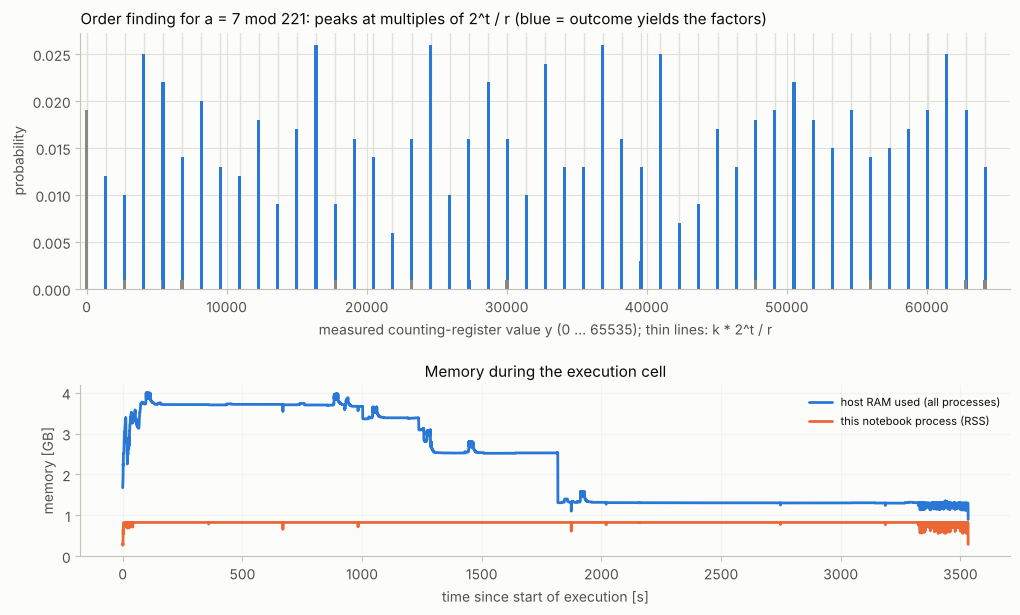

In [12]:
# ---------------------------------------------------------------------------------
# Section 9 - Outcome table, factor verification and plots
# ---------------------------------------------------------------------------------
if not simulate or not execution_ok:
    print("No quantum results: " + (classical_shortcut or "simulation skipped or failed (see above)."))
else:
    last = attempts[-1]
    print(f"Outcomes of the last attempt (a = {last['a']}, t = {n_count}, {SHOTS} shots):")
    print(f"{'y':>8} {'bitstring':<{max(9, n_count)}} {'counts':>6} {'phase y/2^t':>12} {'s/r':>8} {'order r':>8}  factors")
    for row in last["rows"][:16]:
        print(f"{row['y']:>8} {row['bits']:<{max(9, n_count)}} {row['counts']:>6} {row['phase']:>12.5f} "
              f"{str(row['fraction']) if row['fraction'] is not None else '-':>8} {str(row['r']) if row['r'] else '-':>8}  "
              f"{row['factors'] if row['factors'] else '-'}")
    useful = sum(r["counts"] for r in last["rows"] if r["factors"]) / SHOTS
    print(f"\nFraction of shots that directly yield the factors: {useful:.3f}")
    if factors:
        p, q = factors
        print(f"\nRESULT: {N} = {p} x {q}   verification: {p} x {q} = {p * q} -> {'CORRECT' if p * q == N else 'WRONG'}")
    else:
        print(f"\nNo factors found in {len(attempts)} attempt(s); increase MAX_ATTEMPTS or SHOTS.")

    fig = plt.figure(figsize=(12, 6.8))
    grid = fig.add_gridspec(2, 1, height_ratios=[1.2, 0.8], hspace=0.45)
    ax = fig.add_subplot(grid[0])
    ys = np.array([r["y"] for r in last["rows"]])
    cs = np.array([r["counts"] for r in last["rows"]])
    colors = [BLUE if r["factors"] else INK_MUTED for r in last["rows"]]
    width = max(1.0, 2 ** n_count / 300)
    ax.bar(ys, cs / SHOTS, width=width, color=colors)
    r_last = classical_order(last["a"], N)
    for k in range(r_last):
        ax.axvline(k * 2 ** n_count / r_last, color=GRID_COLOR, linewidth=1, zorder=0)
    ax.set_xlim(-2 * width, 2 ** n_count + 2 * width)
    ax.set_xlabel(f"measured counting-register value y (0 ... {2 ** n_count - 1}); thin lines: k * 2^t / r")
    ax.set_ylabel("probability")
    ax.set_title(f"Order finding for a = {last['a']} mod {N}: peaks at multiples of 2^t / r (blue = outcome yields the factors)",
                 loc="left")
    ax_m = fig.add_subplot(grid[1])
    monitor.plot(ax=ax_m, title="Memory during the execution cell")
    plt.show()

---
## Section 10 - Final benchmark report

                                       FINAL BENCHMARK REPORT                                       
Algorithm                           : Shor's algorithm (integer factorization)
Date (UTC)                          : 2026-11-09 06:22:26
CUDA-Q version                      : 0.16.0
Number of qubits                    : 24
Backend (requested -> used)         : cpu -> cpu
CUDA-Q target                       : qpp-cpu
Simulation method                   : statevector
Numerical precision                 : fp64
Number of shots                     : 1000
Circuit construction time           : 0.0353 s
Compilation time (MLIR + JIT)       : 0.5194 s
Quantum execution time              : 3531.8228 s
Total wall time of execution cell   : 3532.5028 s
Timing method                       : CUDA-Q span tracer (first launch)
Peak host RAM used                  : 4.00 GB (23.7% of 16.9 GB)
Peak notebook process RSS           : 0.82 GB (baseline 0.28 GB)
Peak GPU memory                     : not availab

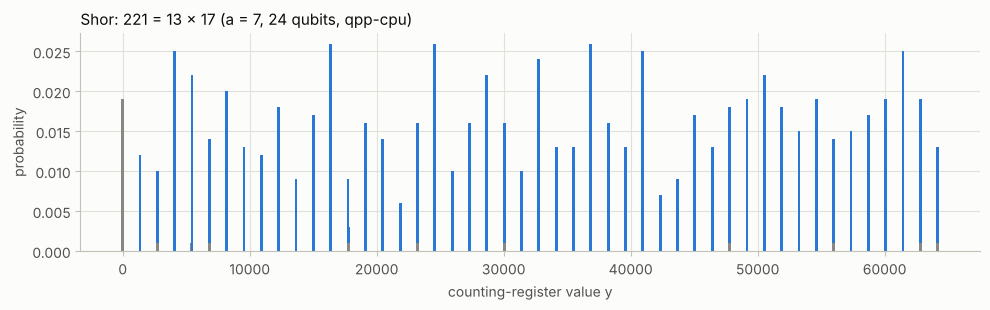

In [13]:
# ---------------------------------------------------------------------------------
# Section 10 - Final benchmark report
# ---------------------------------------------------------------------------------
if not simulate or not execution_ok:
    print("No benchmark report: " + (classical_shortcut or "the quantum simulation was skipped or failed."))
else:
    report = build_report("Shor's algorithm (integer factorization)", backend_cfg, total_qubits, SHOTS, phases, memory)
    report["Integer N / bits"] = f"{N} / {n_work}"
    report["Registers"] = f"{n_count} counting + {n_work} work qubits = {total_qubits}"
    report["Bases tried (a)"] = ", ".join(str(at["a"]) for at in attempts)
    report["Custom modular-multiplication gates"] = ", ".join(attempts[-1]["custom_ops"]) or "none"
    reference = trial_division(N) if N < 10 ** 12 else None
    report["Expected result"] = f"{N} = {reference[0]} x {reference[1]} (trial division)" if reference else "n/a"
    report["Actual result"] = f"{N} = {factors[0]} x {factors[1]}" if factors else "no factors found"
    report["Verification p x q == N"] = ("CORRECT" if factors and factors[0] * factors[1] == N else "FAILED")
    report["Order r found / classical check"] = f"{next((r['r'] for r in attempts[-1]['rows'] if r['factors']), '-')} / {classical_order(attempts[-1]['a'], N)}"
    report["Shots yielding the factors"] = f"{useful:.3f}"
    final_fig, ax = plt.subplots(figsize=(10, 3.2))
    ax.bar(ys, cs / SHOTS, width=width, color=colors)
    ax.set_xlabel("counting-register value y")
    ax.set_ylabel("probability")
    ax.set_title(f"Shor: {N} = {factors[0]} x {factors[1]} (a = {attempts[-1]['a']}, {total_qubits} qubits, {cudaq.get_target().name})"
                 if factors else f"Shor N={N}", loc="left")
    final_fig.tight_layout()
    show_report(report, save=SAVE_REPORT, out_dir=EXPORT_DIR, name="shor_benchmark_report", figure=final_fig)
    plt.show()

---
### Things to try next
* `N_TO_FACTOR = 21`, `BASE_A = 2` (15 qubits): the order $r = 6$ does not divide $2^t$, so the peaks are spread and
  the continued-fraction step does real work.
* `BASE_A = 14` with `N_TO_FACTOR = 15`: $14 \equiv -1$, so $a^{r/2} \equiv -1$ - an unlucky base; the notebook retries.
* `N_TO_FACTOR = 143` (24 qubits) on a GPU, then compare the reports. Each extra bit of $N$ adds 3 qubits = 8x memory.
* Set `N_TO_FACTOR` to an RSA-sized number to see only the resource estimates (no simulation).